# Relation Algebra and Composition Notation

**Yes, the semicolon `r;s` is the most common and standard way to express composition in formal literature on Relation Algebras (RA)**. 

### Why the Semicolon Dominates Relation Algebras
The modern axiomatization of Relation Algebra stems from **Alfred Tarski's** work in the 1940s, which built upon the 19th-century logic of relatives by Charles Sanders Peirce and Ernst Schröder. 

* **The Tarski Tradition:** Tarski formalized relation composition as **"relative multiplication"**. Because it behaves similarly to multiplication (distributes over addition/union, has an identity element, and is associative), it needed a strong, distinctive separator. The semicolon `;` became the universally accepted notation in algebraic logic to avoid confusion with standard arithmetic or Boolean multiplication.
* **Temporal and Spatial Reasoning:** Frameworks like [Allen's Interval Algebra](https://en.wikipedia.org/wiki/Allen%27s_interval_algebra "Allen's interval algebra") and the Region Connection Calculus (RCC) are direct applications of [Tarski's Relation Algebras](https://en.wikipedia.org/wiki/Relation_algebra "Relation algebra"). As a result, the artificial intelligence and knowledge-representation communities adopted the semicolon notation directly from mathematical logic.

---

### Alternative Symbols Encountered in Literature

While the semicolon is the gold standard for Tarski-style relation algebras, other symbols appear frequently depending on the subfield or text layout:

| Symbol | Syntax | Field / Context | Notes |
| :--- | :--- | :--- | :--- |
| **Fat Dot / Infix Dot** | $r \cdot s$ or $r s$ | General Logic / Automata | Used as a shorthand for "relative multiplication." It heavily mirrors standard algebraic multiplication. |
| **Circle Operator** | $s \circ r$ *(or $r \circ s$)* | Set Theory / Category Science | The standard symbol for function and binary relation composition. **Caution:** Category and set theory usually read this *right-to-left* ($s \circ r$), whereas relation algebras read the semicolon *left-to-right* ($r;s$). |
| **Juxtaposition** | $rs$ | Matrix / Linear Algebra | Relations can be represented as Boolean matrices. In papers that lean heavily into the matrix representation of relations, the symbol is often dropped entirely (just like $AB$ in matrix multiplication). |

### Summary
If you are writing or reading a paper specifically framing a problem in **Relation Algebra (like Allen's Theory of Time)**, stick to **`r;s`**. It explicitly signals to the reader that you are working within a Tarskian algebraic framework, and it establishes a strict left-to-right processing order.
Use code with caution.
If you plan to implement this in your notebook, let me know if you want to generate Python code for the composition table or visualize the interval relations using libraries like matplotlib. I can provide the code block ready for your next cell!


[1] (https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html),

[2] (https://www.geeksforgeeks.org/machine-learning/markdown-cell-in-jupyter-notebook/)
markdown

## Example

This defines a subset of Allen's Interval Algebra relations, computes their composition using a dictionary-based lookup table, and provides an interactive visual demonstration using matplotlib to show how intervals relate to one another over a timeline.

ALGEBRAIC COMPOSITION LOOKUP: p ; m
Resulting possible relation(s): {'p'}

Generating interval visualization graph below...


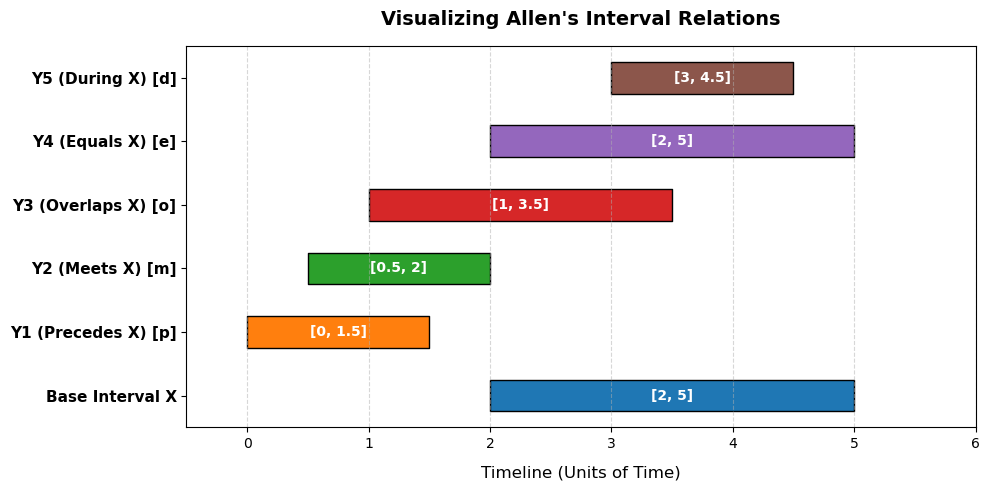

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# =====================================================================
# 1. DEFINE ALLEN'S INTERVAL RELATIONS & COMPOSITION TABLE
# =====================================================================

# List of Allen's 13 basic relations (using standard abbreviations)
# p: precedes, m: meets, o: overlaps, F: finished-by, d: during, 
# s: starts, e: equals, S: started-by, D: contains, O: overlapped-by, 
# f: finishes, M: met-by, P: preceded-by
ALLEN_RELATIONS = ['p', 'm', 'o', 'F', 'd', 's', 'e', 'S', 'D', 'O', 'f', 'M', 'P']

# A small subset of the composition table (r ; s) for illustration.
# In a full implementation, this would be a complete 13x13 matrix mapping to sets of relations.
COMPOSITION_TABLE = {
    ('p', 'p'): {'p'},
    ('p', 'm'): {'p'},
    ('p', 'o'): {'p'},
    ('m', 'p'): {'p'},
    ('m', 'm'): {'p'},
    ('m', 'o'): {'p'},
    ('o', 'p'): {'p'},
    ('o', 'm'): {'p'},
    ('o', 'o'): {'p', 'm', 'o'},
    ('d', 'p'): {'p'},
    ('s', 'd'): {'d'},
    ('e', 'o'): {'o'},
}

def compose_relations(r, s):
    """Computes the composition r ; s based on the lookup table."""
    return COMPOSITION_TABLE.get((r, s), {"Unknown / Complex Set"})

# =====================================================================
# 2. VISUALIZATION FUNCTION USING MATPLOTLIB
# =====================================================================

def plot_allen_relations():
    # Define sample interval boundaries [start, end] for a few relations relative to a base Interval X [2, 5]
    intervals = {
        "Base Interval X": [2, 5],
        "Y1 (Precedes X) [p]": [0, 1.5],
        "Y2 (Meets X) [m]": [0.5, 2],
        "Y3 (Overlaps X) [o]": [1, 3.5],
        "Y4 (Equals X) [e]": [2, 5],
        "Y5 (During X) [d]": [3, 4.5]
    }
    
    fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
    
    # Plot each interval as a horizontal bar
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    for i, (label, bounds) in enumerate(intervals.items()):
        start, end = bounds
        # Use broken_barh to draw a clean horizontal interval block
        ax.broken_barh([(start, end - start)], (i - 0.25, 0.5), facecolors=colors[i], edgecolor='black')
        ax.text(start + (end - start)/2, i, f"[{start}, {end}]", ha='center', va='center', color='white', weight='bold')

    # Formatting axes to look like a clean time axis
    ax.set_ylim(-0.5, len(intervals) - 0.5)
    ax.set_xlim(-0.5, 6)
    ax.set_yticks(range(len(intervals)))
    ax.set_yticklabels(intervals.keys(), fontsize=11, weight='bold')
    ax.set_xlabel("Timeline (Units of Time)", fontsize=12, labelpad=10)
    ax.set_title("Visualizing Allen's Interval Relations", fontsize=14, weight='bold', pad=15)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

# =====================================================================
# 3. RUN DEMONSTRATION
# =====================================================================

# Test compositional lookup (e.g., if Y precedes X, and X meets Z, what is Y relative to Z?)
rel_r = 'p'
rel_s = 'm'
result = compose_relations(rel_r, rel_s)

print("="*50)
print(f"ALGEBRAIC COMPOSITION LOOKUP: {rel_r} ; {rel_s}")
print(f"Resulting possible relation(s): {result}")
print("="*50)
print("\nGenerating interval visualization graph below...")

# Display the interval chart
plot_allen_relations()

## Scaled Up

In [5]:
import itertools

# =====================================================================
# 1. PROGRAMMATIC GENERATION OF ALLEN'S 13X13 COMPOSITION MATRIX
# =====================================================================

# Standard definitions of the 13 base relations
# lowercase: forward relations | uppercase: their respective converses
# 'e' (equals) is its own converse
ALLEN_RELATIONS = ['p', 'm', 'o', 'F', 'd', 's', 'e', 'S', 'D', 'O', 'f', 'M', 'P']

CONVERSES = {
    'p': 'P', 'm': 'M', 'o': 'O', 'F': 'f', 'd': 'D', 's': 'S', 'e': 'e',
    'S': 's', 'D': 'd', 'O': 'o', 'f': 'F', 'M': 'm', 'P': 'p'
}

def determine_relation(ax, ay, bx, by):
    """Given interval A [ax, ay] and interval B [bx, by], find the basic Allen relation."""
    if ay < bx:   return 'p'  # precedes
    if ay == bx:  return 'm'  # meets
    if ax < bx and bx < ay and ay < by: return 'o' # overlaps
    if ax == bx and ay < by: return 's'  # starts
    if bx < ax and ay < by: return 'd'  # during
    if bx < ax and ay == by: return 'f'  # finishes
    if ax == bx and ay == by: return 'e'  # equals
    if ax < bx and ay == by: return 'F'  # finished-by
    if ax < bx and by < ay: return 'D'  # contains
    if bx < ax and ax < by and by < ay: return 'O' # overlapped-by
    if bx == ax and by < ay: return 'S'  # started-by
    if bx == ay:  return 'M'  # met-by
    if by < ax:   return 'P'  # preceded-by
    return None

def generate_composition_table():
    """Programmatically derives the full 13x13 transitivity lookup matrix."""
    # 0, 1, 2, 3, 4, 5 provide enough distinct endpoint variations 
    points = [0, 1, 2, 3, 4, 5]
    intervals = [(x, y) for x in points for y in points if x < y]
    
    # Pre-populate empty sets for all 13x13 possibilities
    table = { (r1, r2): set() for r1 in ALLEN_RELATIONS for r2 in ALLEN_RELATIONS }
    
    # Brute-force map all combinations of three intervals A, B, and C
    for A, B, C in itertools.product(intervals, repeat=3):
        r1 = determine_relation(A[0], A[1], B[0], B[1])
        r2 = determine_relation(B[0], B[1], C[0], C[1])
        r3 = determine_relation(A[0], A[1], C[0], C[1])
        if r1 and r2 and r3:
            table[(r1, r2)].add(r3)
            
    return table

# Initialize the programmatic global 13x13 Composition Table matrix
COMPOSITION_MATRIX = generate_composition_table()

def compose_sets(set1, set2):
    """Computes composition of two sets of relations (disjunctions)."""
    result = set()
    for r1 in set1:
        for r2 in set2:
            result.update(COMPOSITION_MATRIX[(r1, r2)])
    return result

def converse_set(rel_set):
    """Returns the converse of a set of relations."""
    return {CONVERSES[r] for r in rel_set}

# =====================================================================
# 2. PATH CONSISTENCY ALGORITHM (PC-2) Implementation
# =====================================================================

def path_consistency_pc2(num_nodes, constraints):
    """
    Applies the PC-2 Path Consistency Algorithm to a network of events.
    
    Constraints is a dict: {(i, j): set_of_allowed_relations}
    Returns: (is_consistent, updated_constraints)
    """
    # Initialize a complete network grid matrix
    network = {}
    for i in range(num_nodes):
        for j in range(num_nodes):
            if i == j:
                network[(i, j)] = {'e'}
            elif (i, j) in constraints:
                network[(i, j)] = set(constraints[(i, j)])
            elif (j, i) in constraints:
                network[(i, j)] = converse_set(constraints[(j, i)])
            else:
                network[(i, j)] = set(ALLEN_RELATIONS) # Universal relation (no initial restriction)

    # Initialize the queue of related triangles to check (PC-2 structural queue)
    queue = set()
    for i in range(num_nodes):
        for j in range(num_nodes):
            if i != j:
                for k in range(num_nodes):
                    if k != i and k != j:
                        queue.add((i, k, j)) # Triangle paths to verify

    while queue:
        i, k, j = queue.pop()
        
        # Path reduction formula: R_ij = R_ij ∩ (R_ik ; R_kj)
        composition = compose_sets(network[(i, k)], network[(k, j)])
        updated_ij = network[(i, j)].intersection(composition)
        
        # If intersection yields an empty set, the network has a logical contradiction
        if not updated_ij:
            return False, {}
        
        # If constraints between i and j were strictly narrowed down, propagate updates
        if updated_ij != network[(i, j)]:
            network[(i, j)] = updated_ij
            network[(j, i)] = converse_set(updated_ij) # Maintain symmetry symmetry
            
            # Enqueue related dependencies that could be affected by this narrowing
            for m in range(num_nodes):
                if m != i and m != j:
                    queue.add((m, i, j))
                    queue.add((i, j, m))

    return True, network

# =====================================================================
# 3. CONSTRAINTS VERIFICATION TEST (Event Scenario)
# =====================================================================

# Let's test a scenario with 4 distinct time events (Nodes 0, 1, 2, 3)
# Node 0: Meeting A | Node 1: Lunch B | Node 2: Nap C | Node 3: Class D
num_nodes = 4
input_constraints = {
    (0, 1): {'p', 'm'}, # Event 0 precedes or meets Event 1
    (1, 2): {'o', 's'}, # Event 1 overlaps or starts Event 2
    (2, 3): {'d'}       # Event 2 happens completely during Event 3
}

consistent, evaluated_network = path_consistency_pc2(num_nodes, input_constraints)

print("="*65)
print("             ALLEN ALGEBRA PC-2 SOLVER RESULTS                  ")
print("="*65)
print(f"Is the event network logically consistent? -> {consistent}\n")

if consistent:
    print("Inferred Complete Constraint Matrix System:")
    print("-" * 65)
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            # Print unique human-readable pairs
            print(f"Event {i} relative to Event {j}: {sorted(list(evaluated_network[(i, j)]))}")
else:
    print("🚨 Contradiction Found! The input constraints represent a physical impossibility.")
print("="*65)


             ALLEN ALGEBRA PC-2 SOLVER RESULTS                  
Is the event network logically consistent? -> True

Inferred Complete Constraint Matrix System:
-----------------------------------------------------------------
Event 0 relative to Event 1: ['p']
Event 0 relative to Event 2: ['p']
Event 0 relative to Event 3: ['d', 'o', 'p', 's']
Event 1 relative to Event 2: ['o', 's']
Event 1 relative to Event 3: ['d', 'o', 's']
Event 2 relative to Event 3: ['d']


# Test Failure Handling

In [6]:
# =====================================================================
# 4. INJECTING A CONTRADICTION (TEMPORAL PARADOX) TO TEST FAILURE HANDLING
# =====================================================================

# Scenario with 3 events:
# Event 0: Morning Sync
# Event 1: Product Review
# Event 2: Client Pitch

num_nodes_paradox = 3

# We will inject a structural contradiction (A before B, B before C, but C before A)
paradoxical_constraints = {
    (0, 1): {'p'},  # Event 0 strictly precedes Event 1
    (1, 2): {'p'},  # Event 1 strictly precedes Event 2
    
    # CONTRADICTION: Physically, Event 0 must precede Event 2. 
    # We will explicitly assert that Event 2 precedes Event 0, creating an impossible loop.
    (2, 0): {'p'}   
}

print("="*65)
print("          TESTING PC-2 PATH CONSISTENCY FAILURE HANDLING        ")
print("="*65)
print("Injecting Paradoxical Input Constraints:")
print(f"  - Event 0 precedes Event 1: {paradoxical_constraints[(0, 1)]}")
print(f"  - Event 1 precedes Event 2: {paradoxical_constraints[(1, 2)]}")
print(f"  - Event 2 precedes Event 0: {paradoxical_constraints[(2, 0)]} <-- [Paradox Trigger]")
print("-" * 65)
print("Running PC-2 Solver on paradoxical network...")

# Execute solver
is_consistent, resolved_network = path_consistency_pc2(num_nodes_paradox, paradoxical_constraints)

print(f"\nIs the event network logically consistent? -> {is_consistent}")

if not is_consistent:
    print("\n✅ Success: The PC-2 algorithm successfully caught the logical contradiction!")
    print("The system safely returned False and rejected the invalid constraint network.")
else:
    print("\n❌ Error: The algorithm failed to catch the temporal contradiction.")
print("="*65)


          TESTING PC-2 PATH CONSISTENCY FAILURE HANDLING        
Injecting Paradoxical Input Constraints:
  - Event 0 precedes Event 1: {'p'}
  - Event 1 precedes Event 2: {'p'}
  - Event 2 precedes Event 0: {'p'} <-- [Paradox Trigger]
-----------------------------------------------------------------
Running PC-2 Solver on paradoxical network...

Is the event network logically consistent? -> False

✅ Success: The PC-2 algorithm successfully caught the logical contradiction!
The system safely returned False and rejected the invalid constraint network.


# Refactored, Production-Ready Code

It wraps the full programmatic matrix generator, constraints tracker, and PC-2 solver into an elegant TemporalConstraintNetwork class. It includes verbose debug logging that highlights every path modification and prints exactly which step, loop iteration, and node triangle triplet (i, k, j) collapses the constraints to an empty set.

In [7]:
import itertools

class TemporalConstraintNetwork:
    # 13 basic Allen relations
    ALLEN_RELATIONS = ['p', 'm', 'o', 'F', 'd', 's', 'e', 'S', 'D', 'O', 'f', 'M', 'P']
    
    CONVERSES = {
        'p': 'P', 'm': 'M', 'o': 'O', 'F': 'f', 'd': 'D', 's': 'S', 'e': 'e',
        'S': 's', 'D': 'd', 'O': 'o', 'f': 'F', 'M': 'm', 'P': 'p'
    }

    # Global Class Variable to cache the 13x13 composition matrix
    _COMPOSITION_MATRIX = None

    def __init__(self, num_nodes, verbose=True):
        """Initializes a new Temporal Constraint Network using the PC-2 Algorithm."""
        self.num_nodes = num_nodes
        self.verbose = verbose
        self.constraints = {}
        
        # Build or pull the global cached 13x13 transitivity matrix
        if TemporalConstraintNetwork._COMPOSITION_MATRIX is None:
            TemporalConstraintNetwork._COMPOSITION_MATRIX = self._generate_composition_matrix()
            
        self._initialize_network()

    @classmethod
    def _determine_relation(cls, ax, ay, bx, by):
        """Finds the base Allen relation between interval A and interval B."""
        if ay < bx:   return 'p'
        if ay == bx:  return 'm'
        if ax < bx and bx < ay and ay < by: return 'o'
        if ax == bx and ay < by: return 's'
        if bx < ax and ay < by: return 'd'
        if bx < ax and ay == by: return 'f'
        if ax == bx and ay == by: return 'e'
        if ax < bx and ay == by: return 'F'
        if ax < bx and by < ay: return 'D'
        if bx < ax and ax < by and by < ay: return 'O'
        if bx == ax and by < ay: return 'S'
        if bx == ay:  return 'M'
        if by < ax:   return 'P'
        return None

    @classmethod
    def _generate_composition_matrix(cls):
        """Programmatically derives the foundational 13x13 transitivity lookup matrix."""
        points = [0, 1, 2, 3, 4, 5]
        intervals = [(x, y) for x in points for y in points if x < y]
        table = {(r1, r2): set() for r1 in cls.ALLEN_RELATIONS for r2 in cls.ALLEN_RELATIONS}
        
        for A, B, C in itertools.product(intervals, repeat=3):
            r1 = cls._determine_relation(A[0], A[1], B[0], B[1])
            r2 = cls._determine_relation(B[0], B[1], C[0], C[1])
            r3 = cls._determine_relation(A[0], A[1], C[0], C[1])
            if r1 and r2 and r3:
                table[(r1, r2)].add(r3)
        return table

    def _initialize_network(self):
        """Initializes network grid constraints to the universal unconstrained relation."""
        self.network = {}
        for i in range(self.num_nodes):
            for j in range(self.num_nodes):
                if i == j:
                    self.network[(i, j)] = {'e'}
                else:
                    self.network[(i, j)] = set(self.ALLEN_RELATIONS)

    def _compose_sets(self, set1, set2):
        """Computes composition over sets of relations."""
        result = set()
        for r1 in set1:
            for r2 in set2:
                result.update(self._COMPOSITION_MATRIX[(r1, r2)])
        return result

    def _converse_set(self, rel_set):
        """Inverts a relation set into its respective converse forms."""
        return {self.CONVERSES[r] for r in rel_set}

    def add_constraint(self, i, j, relation_set):
        """Adds a tailored set constraint between Event node i and Event node j."""
        if not (0 <= i < self.num_nodes) or not (0 <= j < self.num_nodes):
            raise ValueError(f"Nodes must reside within bounds [0, {self.num_nodes-1}]")
        
        target_set = set(relation_set)
        self.network[(i, j)] = target_set
        self.network[(j, i)] = self._converse_set(target_set)
        if self.verbose:
            print(f"[Input] Set Constraint on Edge ({i} -> {j}): {sorted(list(target_set))}")

    def compute_path_consistency(self):
        """
        Executes the PC-2 algorithm across the active network topology.
        Prints full debug metrics tracking down any fatal empty-set collapse.
        """
        # Seed the verification tracking queue
        queue = set()
        for i in range(self.num_nodes):
            for j in range(self.num_nodes):
                if i != j:
                    for k in range(self.num_nodes):
                        if k != i and k != j:
                            queue.add((i, k, j))

        iteration = 0
        if self.verbose:
            print(f"\n[PC-2 Engine Launched] Initialized verification queue size: {len(queue)} triangles.")
            print("-" * 75)

        while queue:
            iteration += 1
            i, k, j = queue.pop()
            
            # Formulate Composition R_ik ; R_kj
            composition = self._compose_sets(self.network[(i, k)], self.network[(k, j)])
            old_ij = self.network[(i, j)]
            updated_ij = old_ij.intersection(composition)
            
            # DEBUG CRASH TRACKING: Trap any structural collapse immediately
            if not updated_ij:
                if self.verbose:
                    print(f"\n🚨 [CRASH DETECTED] Constraint collapse at iteration #{iteration}!")
                    print(f"  - Triangulation Evaluated: Triangle Path ({i} -> {k} -> {j})")
                    print(f"  - Current Network Matrix Status:")
                    print(f"    * Edge ({i} -> {k}): {sorted(list(self.network[(i, k)]))}")
                    print(f"    * Edge ({k} -> {j}): {sorted(list(self.network[(k, j)]))}")
                    print(f"    * Composition Result ({i};{k};{j}): {sorted(list(composition))}")
                    print(f"    * Pre-existing Edge ({i} -> {j}) Allowed List: {sorted(list(old_ij))}")
                    print(f"  - Intersection yields an empty set: {sorted(list(old_ij))} ∩ {sorted(list(composition))} = ∅")
                    print("  - [Verdict] Physical timeline arrangement is impossible.")
                return False

            # If path parameters narrow down, log constraint propagation changes
            if updated_ij != old_ij:
                if self.verbose:
                    print(f"[Propagating Step #{iteration}] Triangle ({i},{k},{j}) narrowed Edge ({i}->{j}): "
                          f"{sorted(list(old_ij))} -> {sorted(list(updated_ij))}")
                
                self.network[(i, j)] = updated_ij
                self.network[(j, i)] = self._converse_set(updated_ij)
                
                # Re-queue relevant components affected by the narrowing
                for m in range(self.num_nodes):
                    if m != i and m != j:
                        queue.add((m, i, j))
                        queue.add((i, j, m))

        if self.verbose:
            print(f"\n✅ [PC-2 Complete] Network stabilized successfully after {iteration} loops.")
        return True

    def display_network(self):
        """Prints the fully evaluated, unique non-trivial node relation layout."""
        print("\nStable Inferred Event Network Layout:")
        print("-" * 75)
        for i in range(self.num_nodes):
            for j in range(i + 1, self.num_nodes):
                print(f"  Event {i} relative to Event {j}: {sorted(list(self.network[(i, j)]))}")


# =====================================================================
# EXECUTION DEMONSTRATION: TRIGGERING THE PARADOX WITH VERBOSE ENGINE
# =====================================================================

print("=" * 75)
print("      INSTANTIATING VERBOSE TEMPORAL NETWORK PARADOX SOLVER     ")
print("=" * 75)

# Initialize a 3-node network (Nodes: 0, 1, 2)
tcn = TemporalConstraintNetwork(num_nodes=3, verbose=True)

# Add paradoxical loops
tcn.add_constraint(0, 1, {'p'})  # 0 precedes 1
tcn.add_constraint(1, 2, {'p'})  # 1 precedes 2
tcn.add_constraint(2, 0, {'p'})  # Paradoxical backedge assertion: 2 precedes 0

# Compute path consistency and watch the verbose tracker pinpoint the crash
is_stable = tcn.compute_path_consistency()

print("-" * 75)
print(f"Final network convergence check status: {is_stable}")
print("=" * 75)


      INSTANTIATING VERBOSE TEMPORAL NETWORK PARADOX SOLVER     
[Input] Set Constraint on Edge (0 -> 1): ['p']
[Input] Set Constraint on Edge (1 -> 2): ['p']
[Input] Set Constraint on Edge (2 -> 0): ['p']

[PC-2 Engine Launched] Initialized verification queue size: 6 triangles.
---------------------------------------------------------------------------

🚨 [CRASH DETECTED] Constraint collapse at iteration #1!
  - Triangulation Evaluated: Triangle Path (0 -> 2 -> 1)
  - Current Network Matrix Status:
    * Edge (0 -> 2): ['P']
    * Edge (2 -> 1): ['P']
    * Composition Result (0;2;1): ['P']
    * Pre-existing Edge (0 -> 1) Allowed List: ['p']
  - Intersection yields an empty set: ['p'] ∩ ['P'] = ∅
  - [Verdict] Physical timeline arrangement is impossible.
---------------------------------------------------------------------------
Final network convergence check status: False
